# **MC103n Python Programming Project**

## **Prediction of Agricultural Yield given the conditions of 'Area', 'Annual Rainfall', 'Fertilizer', 'Pesticides'**

### **Loading the DataSet(.csv)**

#### For this model we using the dataset of 'Agricultural Crop Yield in Indian States Dataset' from 'Kaggle.com'. Here in this project, I use only specific columns from the whole data to keep things simple.

In [5]:
import pandas as pd

# Whole Data(I will later use some parts of the data)
whole_df = pd.read_csv("C:\\Users\\adity\\OneDrive\\Documents(1)\\DTU\\I-Semester\\MC103 Python\\crop_yield.csv") # I have downloaded the file so i am using a local link here
whole_df

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909
...,...,...,...,...,...,...,...,...,...,...
19684,Small millets,1998,Kharif,Nagaland,4000.0,2000,1498.0,395200.00,1160.00,0.500000
19685,Wheat,1998,Rabi,Nagaland,1000.0,3000,1498.0,98800.00,290.00,3.000000
19686,Maize,1997,Kharif,Jammu and Kashmir,310883.0,440900,1356.2,29586735.11,96373.73,1.285000
19687,Rice,1997,Kharif,Jammu and Kashmir,275746.0,5488,1356.2,26242746.82,85481.26,0.016667


#### Since I am using the linear regression model, the columns that have non-numerical inputs are going to be useless for us here. I am also excluding the columns of 'Crop_Year' and 'Production'. Basically I will be working on four columns of input which are 'Area', 'Annual_Rainfall', 'Fertilizer' and 'Pesticide' and one column of output which is 'Yield'.

In [6]:
whole_df = whole_df[(whole_df['Crop'] == 'Rice')]
df = whole_df.drop(['State', 'Crop', 'Season', 'Crop_Year', 'Production'], axis = 1)
df

,Area,Annual_Rainfall,Fertilizer,Pesticide,Yield
16,607358.0,2051.4,5.780226e+07,188280.98,0.780870
17,174974.0,2051.4,1.665228e+07,54241.94,1.060435
18,1743321.0,2051.4,1.659119e+08,540429.51,0.941304
51,1031530.0,1266.7,9.817071e+07,319774.30,2.233500
52,53889.0,1266.7,5.128616e+06,16705.59,2.073846
...,...,...,...,...,...
19670,454370.0,1635.9,7.369881e+07,159029.50,1.322917
19671,274230.0,1635.9,4.448011e+07,95980.50,2.586071
19672,3130820.0,1635.9,5.078190e+08,1095787.00,1.982333
19683,141000.0,1498.0,1.393080e+07,40890.00,1.441429


### **Preparing the data**

#### I am going to prepare the data which we will use as input, output, training and testing.

#### **Data Separation**

In [7]:
y = df['Yield'] # Output data
y

16       0.780870
17       1.060435
18       0.941304
51       2.233500
52       2.073846
           ...   
19670    1.322917
19671    2.586071
19672    1.982333
19683    1.441429
19687    0.016667
Name: Yield, Length: 1197, dtype: float64

In [8]:
x = df.drop('Yield', axis = 1) # axis=1 tells Pandas that you are dropping columns (not rows)
x

,Area,Annual_Rainfall,Fertilizer,Pesticide
16,607358.0,2051.4,5.780226e+07,188280.98
17,174974.0,2051.4,1.665228e+07,54241.94
18,1743321.0,2051.4,1.659119e+08,540429.51
51,1031530.0,1266.7,9.817071e+07,319774.30
52,53889.0,1266.7,5.128616e+06,16705.59
...,...,...,...,...
19670,454370.0,1635.9,7.369881e+07,159029.50
19671,274230.0,1635.9,4.448011e+07,95980.50
19672,3130820.0,1635.9,5.078190e+08,1095787.00
19683,141000.0,1498.0,1.393080e+07,40890.00


#### **Data Splitting**

In [9]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 100) 
# The initial variable names are not fixed but the order is important.
# This is the method used to split the data into training and testing ones. We are keeping test_data size 20% as standard. 

In [10]:
x_train # 80% of data

,Area,Annual_Rainfall,Fertilizer,Pesticide
8643,59196.0,2499.5000,5.859220e+06,14207.04
18982,148.0,3095.2000,1.974320e+04,23.68
19235,268081.0,1357.1000,2.648640e+07,77743.49
706,42779.0,1434.5875,4.199614e+06,11122.54
6482,82125.0,1381.6000,8.113950e+06,23816.25
...,...,...,...,...
13728,763205.0,605.6000,1.152134e+08,251857.65
654,55258.0,2412.6000,5.424678e+06,14367.08
5257,27219.0,2772.5000,4.285359e+06,10343.22
1051,2109301.0,648.1000,1.996875e+08,527325.25


In [11]:
x_test

,Area,Annual_Rainfall,Fertilizer,Pesticide
18619,15691.0,2804.1,1.493312e+06,4864.21
17669,3375000.0,1290.4,3.656475e+08,708750.00
13994,920307.0,746.4,1.389295e+08,303701.31
8335,4090.0,1610.3,3.872003e+05,1022.50
12811,306.0,2050.2,4.614480e+04,94.86
...,...,...,...,...
15515,52616.0,814.8,8.283863e+06,19994.08
11068,21000.0,618.0,3.272220e+06,3570.00
19614,3226450.0,1460.5,4.944535e+08,1129257.50
5896,1878208.0,2084.7,3.226010e+08,694936.96


In [12]:
y_train

8643     1.925000
18982    1.264000
19235    1.582667
706      2.605000
6482     1.455455
           ...   
13728    1.867368
654      2.230000
5257     2.635000
1051     2.202727
13543    3.353333
Name: Yield, Length: 957, dtype: float64

In [13]:
y_test

18619    1.365000
17669    1.511333
13994    2.958889
8335     2.800000
12811    2.352500
           ...   
15515    2.657857
11068    3.034444
19614    2.543000
5896     2.137037
2150     2.497857
Name: Yield, Length: 240, dtype: float64

### **Model Building**

### We are using the linear regression model. Linear Regression is one of the simplest and most fundamental supervised machine learning algorithms. Its main job is to predict a continuous, numerical value (y)—like a crop yield, house price, or temperature—based on one or more input features (x).                                                                                                                                                    Linear Regression is literally just finding the equation of a straight line: y = mx + c                                                              

#### Or in machine learning terms: y = w_1x + b, where w_1 is the slope/weight and b is the y-intercept/bias.                                               
#### Even when you give the model multiple columns (like Area, Annual Rainfall, Fertilizer, and Pesticide), Linear Regression is fundamentally still just calculating weights (m) and an intercept (c)—it just does it for each column simultaneously.

#### When you give it multiple columns, the equation simply gets a separate slope (m) for each feature:

####      Yield = (m_1 * Area) + (m_2 * Rainfall) + (m_3 * Fertilizer) + (m_4 * Pesticide) + c

### Finding the Best Weights (m_1, m_2, ...):
#### Instead of finding a single slope on a 2D flat graph, the computer calculates a multi-dimensional line (called a hyperplane) that minimizes the total error across all your data rows.Weighing What Matters Most:
#### If Fertilizer has a massive impact on crop yield, its m value (coefficient) will be larger. If a feature turns out to be completely useless, its m value will be very close to zero.The Intercept (c):
#### This is just the baseline starting yield if all your input features happened to be zero.


#### **Model Training**

In [14]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-0.,-0., 0., 0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Area','Annual_Rainfall','Fertilizer','Pesticide']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.444
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


#### **Applying the model to make Predictions**

In [15]:
y_lr_train_pred = lr.predict(x_train)
y_lr_test_pred = lr.predict(x_test)

In [16]:
y_lr_train_pred

array([2.13738339, 2.07573489, 2.24624218, 2.26688672, 2.26848385,
       2.27496849, 2.25501803, 2.37165587, 2.54893125, 2.28166674,
       2.37139637, 1.77300316, 2.33811136, 2.63887127, 2.39576406,
       1.69881694, 2.06220401, 2.0630618 , 2.13877383, 2.17417495,
       2.19082351, 2.2728527 , 1.71259933, 2.32670345, 2.16384985,
       1.99698232, 2.05513871, 2.32452237, 2.01504955, 2.32088104,
       2.24318565, 2.13316842, 2.27359017, 1.98047398, 2.03892571,
       2.36168373, 2.27269962, 2.27019087, 2.38604885, 2.22363215,
       2.36211508, 2.20635622, 2.16996304, 2.4348318 , 2.33341764,
       2.14654436, 2.00108282, 2.34505672, 2.48727616, 2.40819426,
       2.31868058, 2.14192296, 2.30136874, 2.18484401, 2.26938304,
       1.91412748, 1.66936336, 2.34660267, 2.24692057, 2.09529111,
       2.14930593, 2.21304165, 1.92933718, 2.48572574, 2.41060522,
       2.40679953, 1.93155524, 2.07094585, 2.38748415, 1.93878082,
       1.94408987, 2.02901311, 2.31472475, 2.080164  , 1.95241

In [17]:
y_test

18619    1.365000
17669    1.511333
13994    2.958889
8335     2.800000
12811    2.352500
           ...   
15515    2.657857
11068    3.034444
19614    2.543000
5896     2.137037
2150     2.497857
Name: Yield, Length: 240, dtype: float64

In [18]:
y_lr_test_pred

array([2.1082291 , 1.80917225, 2.37933739, 2.25171901, 2.20006432,
       2.35635166, 2.36805665, 2.09196585, 2.28695867, 2.19868329,
       2.3227137 , 2.29423177, 2.17860853, 2.36519446, 2.1301959 ,
       2.34347644, 1.9774771 , 2.30610134, 2.27643867, 2.26466739,
       2.15468494, 2.14716972, 2.04562006, 1.92152267, 1.83523674,
       2.10096328, 2.187487  , 2.08180001, 2.09622928, 2.27251722,
       2.20851229, 2.31082874, 2.2989137 , 2.22342639, 1.92977143,
       2.21582089, 2.32289328, 2.28870072, 2.29939546, 2.25044444,
       2.28884455, 2.32340019, 2.23661182, 1.98536073, 2.27832902,
       2.33426346, 2.1497584 , 1.98410745, 2.05645872, 2.29231273,
       2.12597564, 2.27755596, 2.2690288 , 1.8296797 , 2.20450892,
       2.21146693, 2.14917447, 2.0578868 , 2.26858611, 1.91110158,
       2.31370247, 2.29730802, 2.10785864, 2.04875485, 2.20960891,
       1.79325965, 1.98271018, 2.15431621, 2.28053996, 2.42385222,
       2.1326319 , 2.14060428, 2.29342897, 2.25598981, 2.35462

#### **Evaluate Model Performance**

#### MSE(Mean Squared ERROR) measures the average squared difference between our model's predictions and the actual values. Because it squares the errors, larger mistakes are penalized much more heavily than small ones. It tells us how far off our predictions are from reality, on average, in units squared.                                                                                                                                          Closer to 0 is better: An MSE of 0 means our model has zero error and every prediction was 100% spot on.                                               Higher numbers mean worse errors: The higher the MSE, the worse the model's accuracy.                                                                   
#### R^2 measures how much of the variance in your target variable (y) is explained by your input features (x). It compares your model's performance to a baseline model that just guesses the flat average of the data. It tells us how good our model is compared to a lazy "guess the average" baseline.  1.0 (or 100%): A perfect model that explains 100% of the variation.                                                                                    0.0: Your model is doing no better than just predicting the flat average.                                                                              Between 0 and 1 (e.g., 0.75): Good!

In [19]:
from sklearn.metrics import mean_squared_error, r2_score

lr_train_mse = mean_squared_error(y_train, y_lr_train_pred)
lr_train_r2 = r2_score(y_train, y_lr_train_pred)

lr_test_mse = mean_squared_error(y_test, y_lr_test_pred)
lr_test_r2 = r2_score(y_test, y_lr_test_pred)

In [20]:
print('LR MSE (Train): ', lr_train_mse)
print('LR R2 (Train): ', lr_train_r2)
print('LR MSE (Test): ', lr_test_mse)
print('LR R2 (Test): ', lr_test_r2)

LR MSE (Train):  0.6208999422410328
LR R2 (Train):  0.048179165607750485
LR MSE (Test):  0.5903227003731409
LR R2 (Test):  0.02583069109377989


### **Data Visualisation of Results**

Text(0.5, 0, 'Actual Yield')

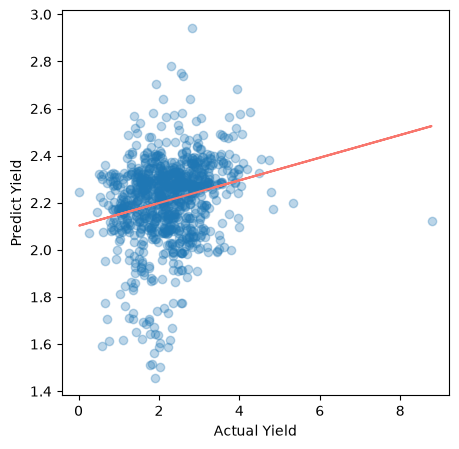

In [23]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(5,5))
plt.scatter(x=y_train, y = y_lr_train_pred, alpha=0.3)

z = np.polyfit(y_train, y_lr_train_pred, 1)
p = np.poly1d(z)

plt.plot(y_train, p(y_train), '#F8766D')
plt.ylabel('Predict Yield')
plt.xlabel('Actual Yield')
# plt.figure(figsize=(5,5))
# plt.scatter(x=y_test, y = y_lr_test_pred, alpha=0.3)

# z = np.polyfit(y_test, y_lr_test_pred, 1)
# p = np.poly1d(z)

# plt.plot(y_test, p(y_test), '#F8766D')
# plt.ylabel('Predict Yield')
# plt.xlabel('Actual Yield')